# Life cycle assessment
Would this setup also reduce my carbon footprint? This depends on how much carbon is embedded in the production, use and recycling of the solar panels (life cycle assessment) compared with the carbon intensity of the Belgian electrical grid. 
The IEA proposes a value of 35.8 gCO2e/kWh for monocrystal solar panels, over a 30 year lifetime. Considering an average annual production of 557.88 kWh, over 30 years this would correspond to 16.74 MWh, or 599.16 kg of CO2e emissions prevented.

The carbon intensity of the Belgian electrical grid varies in time depending on the specific energy mix. It gets low when the grid is powered by renewable energy, and it increases when natural gas is burnt to generate energy. In theory, this means that to get a precise calculation of the avoided carbon emissions I should consider the hourly variation of carbon intensity.

In [6]:
annual_energy = 557.88 # kWh/year
lifetime = 30 # years
lifetime_energy = annual_energy * lifetime
carbon_intensity = 35.8 # gCO2e/kWh

embodied_carbon = carbon_intensity * lifetime_energy / 1000  # kg CO2e
print(f'Annual energy: {annual_energy:.2f} kWh/year')
print(f'Lifetime energy: {lifetime_energy:.2f} kWh')
print(f'Embodied carbon: {embodied_carbon:.2f} kg CO2e')
print(f'Carbon intensity: {carbon_intensity:.2f} gCO2e/kWh')

Annual energy: 557.88 kWh/year
Lifetime energy: 16736.40 kWh
Embodied carbon: 599.16 kg CO2e
Carbon intensity: 35.80 gCO2e/kWh


Average carbon intensity: 143.61 gCO2e/kWh
Avoided carbon: 2403.52 kg CO2e
Net carbon: -1804.36 kg CO2e


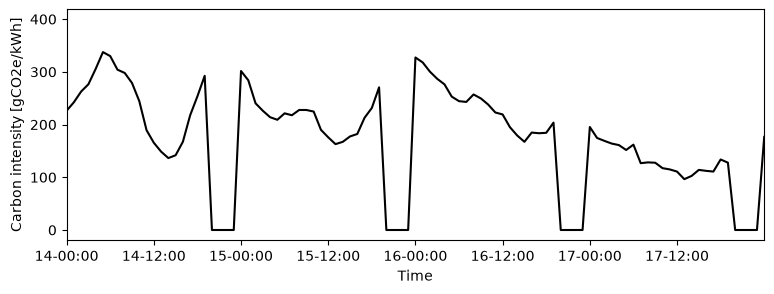

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

grid_intensity = pd.read_csv("../data/ods192.csv", parse_dates=True, sep=";")
grid_intensity["Datetime"] = pd.to_datetime(grid_intensity["Datetime"], format="ISO8601", utc=True).dt.tz_convert("Europe/Brussels")
grid_intensity = grid_intensity.set_index("Datetime")

tz = "Europe/Brussels"

average_intensity = grid_intensity["Consumption"].mean()
print(f'Average carbon intensity: {average_intensity:.2f} gCO2e/kWh')

avoided_carbon = lifetime_energy * average_intensity / 1000  # kg CO2e
print(f'Avoided carbon: {avoided_carbon:.2f} kg CO2e')
print(f'Net carbon: {embodied_carbon - avoided_carbon:.2f} kg CO2e')

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(grid_intensity.index, grid_intensity["Consumption"], c='k')
ax.set_xlabel("Time")
ax.set_ylabel("Carbon intensity [gCO2e/kWh]")   
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%H:%M", tz=tz))
day_start = pd.Timestamp("2026-10-14 00:00", tz=tz)
day_end = pd.Timestamp("2026-10-17 23:59", tz=tz)
ax.set_xlim(day_start, day_end)
plt.show()

However, to obtain a first order approximation, I will consider the average carbon intensity of the last 3 years, which is equal to 143.61 g/CO2e/kWh, or almost 5 times higher than the solar panel’s carbon intensity. In the end, this means that over its lifetime, the solar panel would avoid the emission of roughly 1800 kg CO2e. 

From a carbon footprint the solar panel is certainly better than nothing, but it is sobering to consider that 2 tonnes of CO2 is less than what a single airplane emits for a medium haul flight.
